# Commitment: confirming the win, checking the blast radius, and the collapse

`commitment-sweep.ipynb` found that `commitment=0` beats the default of 2 on
every KPI — 93.4% vs 91.3% served, 469.6s vs 504.7s mean wait — and that
`commitment=8` collapses the policy outright (63.4% served, 89% of insertions
rejected). Three things have to happen before any of that changes a default or
a baseline.

**Part A — is the win real, and does it survive load?** The served-fraction
confidence intervals in the sweep only barely separated. But every level ran
the same seeds, so the comparison is **paired** and a per-trial difference is
far more sensitive than two overlapping intervals. Plus one check at 500
requests.

**Part B — does `commitment=0` harm anything else?** `commitment` is a
`run_trial` parameter shared by every policy. `WindowInsertionPolicy` keeps a
persistent schedule so its route cannot thrash, but the stateless policies have
no such protection and may genuinely need the locked prefix. If they degrade,
the default must stay where it is and `commitment=0` becomes a
`WindowInsertionPolicy`-only setting.

**Part C — is the collapse governed by the service window?** The proposed
mechanism is arithmetic: the policy plans from a clock roughly
`commitment x median_hop` seconds into the future, so once that exceeds the
service window, every newly created request is already past its deadline
before the search begins. That predicts the breakdown point moves when the
window moves. Three windows test it.

## Why Part C is worth the compute

If the collapse is window-governed it is a **transferable design rule** —
"keep the committed prefix short relative to the service window" — which
carries to any map and any patience level. If it sits at 6–8 stops regardless
of the window, it is a fact about this map's geometry and worth nothing
elsewhere. Same experimental logic as Q2 in `window-width-sweep-2.ipynb`:
sweeping one knob cannot distinguish the two, moving the other knob can.

In [1]:
%matplotlib inline
# Static comparison charts only, so the inline backend is all we need.

import statistics
import time
from collections import defaultdict
from dataclasses import dataclass, field
from itertools import permutations
from typing import Callable

import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import Markdown, display

from src.algorithm.DispatchPolicy import BusState, DispatchPolicy
from src.algorithm.FixedRoutePolicy import FixedRoutePolicy
from src.algorithm.NearestUnservedPolicy import NearestUnservedPolicy
from src.algorithm.RequestPool import Request
from src.algorithm.Schedule import Schedule
from src.algorithm.SkipStopFixedRoutePolicy import SkipStopFixedRoutePolicy
from src.algorithm.WindowInsertionPolicy import WindowInsertionPolicy
from src.experiment import (
    ComparisonSummary,
    TrialResult,
    run_trial,
    summarize_comparison,
)
from src.map.PlanarMapProvider import PlanarMapProvider
from src.map.TransitGraph import TransitGraph
from src.map.graph import PlanarStreetGraph


@dataclass
class Tally:
    """
    Insertion counters for one experimental column.

    Only what Part C needs: the collapse story predicts the rejection rate
    explodes at the same point the served fraction falls, and two independent
    readouts of one threshold are much harder to explain away than one.

    :param plan_calls: Completed calls to ``plan``.
    :param insertion_attempts: Calls to ``_best_insertion``.
    :param rejections: Attempts that found no feasible slot pair.
    :param owner_counts: Distinct requests in the schedule, one sample per
        plan call.
    """

    plan_calls: int = 0
    insertion_attempts: int = 0
    rejections: int = 0
    owner_counts: list[int] = field(default_factory=list)


# Keyed by column label, which must stay unique across all three parts.
STATS: dict[str, Tally] = defaultdict(Tally)


class InstrumentedPolicy(WindowInsertionPolicy):
    """
    WindowInsertionPolicy that records its insertion outcomes.

    Behaviourally identical to its parent: both overrides count, then
    delegate straight up.
    """

    def __init__(
        self,
        graph: TransitGraph,
        label: str,
        max_wait_s: float,
        **kwargs: float,
    ) -> None:
        """
        :param graph: Transit graph, forwarded to the parent.
        :param label: Column label these counts are filed under.
        :param max_wait_s: Service window in seconds.
        :param kwargs: Any other WindowInsertionPolicy argument.
        """
        super().__init__(graph, max_wait_s=max_wait_s, **kwargs)
        self._label = label

    def plan(self, state: BusState, n_stops: int) -> list[str]:
        """Plan normally, then sample the resulting schedule."""
        route = super().plan(state, n_stops)
        tally = STATS[self._label]
        tally.plan_calls += 1
        tally.owner_counts.append(len(self.schedule.owners()))
        return route

    def _best_insertion(
        self, schedule: Schedule, request: Request, state: BusState
    ) -> Schedule | None:
        """Insert normally, then record whether the request was rejected."""
        result = super()._best_insertion(schedule, request, state)
        tally = STATS[self._label]
        tally.insertion_attempts += 1
        if result is None:
            tally.rejections += 1
        return result


def window_factory(
    label: str, window: float
) -> Callable[[TransitGraph], InstrumentedPolicy]:
    """
    Build an instrumented WindowInsertionPolicy factory.

    A named closure rather than a lambda, so the late-binding trap that bites
    list comprehensions cannot arise.
    :param label: Column label the counts are filed under.
    :param window: Service window in seconds.
    :return: Callable taking a TransitGraph and returning a policy.
    """
    def factory(graph: TransitGraph) -> InstrumentedPolicy:
        return InstrumentedPolicy(graph, label=label, max_wait_s=window)
    return factory


BASE_SEED = 0
WINDOW_S = 900.0

# run_trial kwargs matching every previous campus experiment. NOTE: max_wait_s
# here is the *backend's abandonment threshold*, a different quantity from the
# policy's service window; they coincide at 900s deliberately.
LOAD_200 = dict(max_requests=200, capacity=40, max_wait_s=900.0)
LOAD_500 = dict(max_requests=500, capacity=40, max_wait_s=900.0)

## 1. Shared map, and the median hop

Same `MAP_SEED` and configuration as every previous sweep. The median
inter-stop cost is computed here rather than quoted, because Part C's
prediction is stated in units of it.

This is the same quantity `WindowInsertionPolicy._baseline_stop_cost` derives
its default window from: the median over **all ordered pairs** of stops. Worth
noting that this overestimates the leg the bus actually drives, since the
policy chooses nearby stops rather than random ones — see the Part C reading
notes.

In [2]:
MAP_SEED = 42

graph = PlanarStreetGraph.generate(
    n_seeds=17,
    bounds=(0.0, 0.0, 2000.0, 2000.0),
    seed=MAP_SEED,
    stop_density=0.5,
)

provider = PlanarMapProvider(graph)
transit_graph = TransitGraph(provider)

stop_ids = [stop.edge.id for stop in transit_graph.get_stops()]
MEDIAN_HOP_S = statistics.median([
    transit_graph.best_path_cost(origin, destination)
    for origin, destination in permutations(stop_ids, 2)
])

print(f"{len(stop_ids)} bus stops on this map")
print(f"Median ordered-pair stop-to-stop cost: {MEDIAN_HOP_S:.1f} s")
print(f"Predicted collapse commitment at W{int(WINDOW_S)}: "
      f"{WINDOW_S / MEDIAN_HOP_S:.1f} stops")

21 bus stops on this map
Median ordered-pair stop-to-stop cost: 132.1 s
Predicted collapse commitment at W900: 6.8 stops


## 2. Cost check

Three parts, and Part C is 24 columns. One trial is timed at each part's most
expensive configuration before committing.

The probes file under throwaway labels and only those keys are popped, so this
cell is safe to run in any order.

In [3]:
N_TRIALS_A = 20
N_TRIALS_B = 20
# Part C measures a collapse from ~93% to ~63%. That is an enormous effect
# next to Part A's two-point difference, so it needs far fewer trials to
# resolve and 24 columns make the saving worth taking.
N_TRIALS_C = 12

PART_C_WINDOWS = [600.0, 900.0, 1350.0]
# Chosen to bracket the predicted threshold for all three windows
# (600/132 ~ 4.5, 900/132 ~ 6.8, 1350/132 ~ 10.2) while staying under the
# n_stops=20 planning horizon.
PART_C_COMMITMENTS = [0, 2, 4, 6, 8, 10, 12, 14]

PROBES = {
    "A / 200 req": dict(commitment=0, window=WINDOW_S, load=LOAD_200),
    "A / 500 req": dict(commitment=0, window=WINDOW_S, load=LOAD_500),
    "C / widest window": dict(
        commitment=0,
        window=max(PART_C_WINDOWS),
        load=dict(max_requests=200, capacity=40,
                  max_wait_s=max(PART_C_WINDOWS)),
    ),
}

probe_costs: dict[str, float] = {}
for probe_name, probe in PROBES.items():
    label = f"probe {probe_name}"
    start = time.perf_counter()
    run_trial(
        policy_factory=window_factory(label, probe["window"]),
        graph=graph,
        seed=BASE_SEED,
        silent=True,
        commitment=probe["commitment"],
        **probe["load"],
    )
    probe_costs[probe_name] = time.perf_counter() - start
    STATS.pop(label, None)

# Upper bounds: Part B's fixed-route columns are cheaper than the insertion
# policy this is priced against, and most Part C columns are cheaper than its
# widest-window, zero-commitment corner.
part_a = N_TRIALS_A * 2 * (
    probe_costs["A / 200 req"] + probe_costs["A / 500 req"]
)
part_b = N_TRIALS_B * 8 * probe_costs["A / 200 req"]
part_c = (
    N_TRIALS_C * len(PART_C_WINDOWS) * len(PART_C_COMMITMENTS)
    * probe_costs["C / widest window"]
)

display(Markdown("\n".join(
    [f"- One trial, **{name}**: {cost:.1f} s"
     for name, cost in probe_costs.items()]
    + ["",
       f"Upper bound — Part A: **{part_a / 60:.1f} min**, "
       f"Part B: **{part_b / 60:.1f} min**, "
       f"Part C: **{part_c / 60:.1f} min**",
       f"Total: **{(part_a + part_b + part_c) / 60:.1f} min**"]
)))

- One trial, **A / 200 req**: 2.0 s
- One trial, **A / 500 req**: 4.6 s
- One trial, **C / widest window**: 1.8 s

Upper bound — Part A: **4.4 min**, Part B: **5.4 min**, Part C: **8.8 min**
Total: **18.6 min**

## Part A — is the win real?

Four runs: `commitment` 0 and 2, at 200 and 500 requests. Every run uses
`base_seed=0` and the same trial count, so trial *i* faces the same demand
sequence in all four. That makes the comparison paired, and the per-trial
difference is the statistic to read — not the overlap of two independent
intervals.

**Regression check:** `commitment=2 / 200 req` should reproduce the sweep
exactly — 182.7 fulfilled, 504.7s mean wait, 91.3% served.

In [4]:
PART_A_LOADS = {"200 req": LOAD_200, "500 req": LOAD_500}
PART_A_COMMITMENTS = [0, 2]


def part_a_label(load_name: str, commitment: int) -> str:
    """
    Column label for one Part A cell.
    :param load_name: Demand level, as keyed in PART_A_LOADS.
    :param commitment: Number of leading stops locked during re-planning.
    :return: The label STATS and the summaries are keyed by.
    """
    return f"A {load_name} c{commitment}"


part_a_summaries: dict[tuple[str, int], ComparisonSummary] = {}
for load_name, load_kwargs in PART_A_LOADS.items():
    for commitment in PART_A_COMMITMENTS:
        label = part_a_label(load_name, commitment)
        part_a_summaries[(load_name, commitment)] = summarize_comparison(
            policies=[(label, window_factory(label, WINDOW_S))],
            graph=graph,
            n_trials=N_TRIALS_A,
            base_seed=BASE_SEED,
            commitment=commitment,
            **load_kwargs,
        )

A 200 req c0:   0%|          | 0/20 [00:00<?, ?it/s]

A 200 req c2:   0%|          | 0/20 [00:00<?, ?it/s]

A 500 req c0:   0%|          | 0/20 [00:00<?, ?it/s]

A 500 req c2:   0%|          | 0/20 [00:00<?, ?it/s]

In [5]:
def trials_of(summary: ComparisonSummary) -> list[TrialResult]:
    """
    Unwrap the single policy column a summary was built from.
    :param summary: A ComparisonSummary holding exactly one column.
    :return: That column's per-trial results.
    """
    (only_column,) = summary.results.values()
    return only_column


def paired_delta(
    baseline: list[TrialResult],
    treatment: list[TrialResult],
    extract: Callable[[TrialResult], float | None],
) -> tuple[float, float, float]:
    """
    Mean per-trial difference (treatment - baseline) with a CI and a p-value.

    Trials are paired by index, which is meaningful because every column ran
    the same base_seed and trial count, so trial i faced the same demand
    sequence in both.
    :param baseline: Per-trial results for the reference column.
    :param treatment: Per-trial results for the column being tested.
    :param extract: Maps a TrialResult to the scalar being compared, or None
        when that trial does not define it.
    :return: (mean difference, 95% CI half-width, two-sided paired p-value).
        The last two are NaN with fewer than two usable pairs.
    """
    pairs = [
        (before, after)
        for base_trial, treat_trial in zip(baseline, treatment)
        if (before := extract(base_trial)) is not None
        and (after := extract(treat_trial)) is not None
    ]
    if not pairs:
        return float("nan"), float("nan"), float("nan")

    differences = [after - before for before, after in pairs]
    mean_difference = statistics.fmean(differences)
    if len(differences) < 2:
        return mean_difference, float("nan"), float("nan")

    half_width = (
        stats.t.ppf(0.975, len(differences) - 1)
        * statistics.stdev(differences)
        / len(differences) ** 0.5
    )
    p_value = float(stats.ttest_rel(
        [after for _, after in pairs],
        [before for before, _ in pairs],
    ).pvalue)
    return mean_difference, half_width, p_value


# (display name, extractor, which direction counts as an improvement)
_MetricSpec = tuple[str, Callable[[TrialResult], float | None], str]

PART_A_METRICS: list[_MetricSpec] = [
    ("Fulfilled requests", lambda r: float(r.kpi.fulfilled_count), "higher"),
    ("Served fraction (pp)",
     lambda r: None if r.kpi.served_fraction is None
     else 100.0 * r.kpi.served_fraction, "higher"),
    ("Mean wait (s)", lambda r: r.kpi.mean_wait_time, "lower"),
    ("Mean ride (s)", lambda r: r.kpi.mean_ride_time, "lower"),
    ("Max ride (s)",
     lambda r: max(r.ride_times) if r.ride_times else None, "lower"),
]

lines = [
    "| Load | Metric | c=2 (default) | c=0 | Delta (c0 - c2) | p |",
    "| --- | --- | --- | --- | --- | --- |",
]
for load_name in PART_A_LOADS:
    baseline = trials_of(part_a_summaries[(load_name, 2)])
    treatment = trials_of(part_a_summaries[(load_name, 0)])
    for metric_name, extract, better in PART_A_METRICS:
        base_values = [
            value for trial in baseline
            if (value := extract(trial)) is not None
        ]
        treat_values = [
            value for trial in treatment
            if (value := extract(trial)) is not None
        ]
        delta, half_width, p_value = paired_delta(
            baseline, treatment, extract
        )
        improved = delta > 0 if better == "higher" else delta < 0
        marker = "**" if p_value < 0.05 and improved else ""
        lines.append(
            f"| {load_name} | {metric_name} "
            f"| {statistics.fmean(base_values):.1f} "
            f"| {statistics.fmean(treat_values):.1f} "
            f"| {marker}{delta:+.1f} ± {half_width:.1f}{marker} "
            f"| {p_value:.4f} |"
        )
display(Markdown("\n".join(lines)))
display(Markdown(
    "*Bold marks a difference that is both significant at p < 0.05 and in "
    "the favourable direction. The CI is the 95% half-width on the paired "
    "difference.*"
))

| Load | Metric | c=2 (default) | c=0 | Delta (c0 - c2) | p |
| --- | --- | --- | --- | --- | --- |
| 200 req | Fulfilled requests | 182.7 | 186.8 | **+4.0 ± 2.3** | 0.0018 |
| 200 req | Served fraction (pp) | 91.3 | 93.4 | **+2.0 ± 1.2** | 0.0018 |
| 200 req | Mean wait (s) | 504.7 | 469.6 | **-35.0 ± 11.6** | 0.0000 |
| 200 req | Mean ride (s) | 564.5 | 543.6 | -20.9 ± 36.6 | 0.2463 |
| 200 req | Max ride (s) | 2995.4 | 2752.5 | -242.9 ± 416.6 | 0.2373 |
| 500 req | Fulfilled requests | 455.8 | 464.9 | **+9.1 ± 4.2** | 0.0002 |
| 500 req | Served fraction (pp) | 91.2 | 93.0 | **+1.8 ± 0.8** | 0.0002 |
| 500 req | Mean wait (s) | 500.5 | 469.3 | **-31.2 ± 8.7** | 0.0000 |
| 500 req | Mean ride (s) | 571.2 | 538.1 | **-33.1 ± 21.0** | 0.0039 |
| 500 req | Max ride (s) | 3385.2 | 3189.9 | -195.3 ± 336.5 | 0.2394 |

*Bold marks a difference that is both significant at p < 0.05 and in the favourable direction. The CI is the 95% half-width on the paired difference.*

## Part B — does `commitment=0` harm anything else?

Four policies at `commitment` 0 and 2. The two cycle-based policies should be
close to indifferent — their visit order comes from the cycle, not from
re-planning — so they act as a negative control. `NearestUnservedPolicy` is
the thrash risk: it is stateless and purely greedy, so nothing stops it
re-targeting a different nearest stop on every arrival, which is exactly what
a committed prefix exists to damp.

**Regression check:** `WindowInsertion` at `c=2` should again land on 91.3%
served.

In [6]:
PART_B_POLICIES: list[tuple[str, Callable[[TransitGraph], DispatchPolicy]]] = [
    ("Fixed route", lambda g: FixedRoutePolicy(g)),
    ("Fixed route w/ skip", lambda g: SkipStopFixedRoutePolicy(g)),
    ("Nearest unserved", lambda g: NearestUnservedPolicy(g)),
    ("Window insertion", lambda g: WindowInsertionPolicy(
        g, max_wait_s=WINDOW_S)),
]

part_b_summaries: dict[int, ComparisonSummary] = {}
for commitment in [0, 2]:
    part_b_summaries[commitment] = summarize_comparison(
        policies=[
            (f"{name} c{commitment}", factory)
            for name, factory in PART_B_POLICIES
        ],
        graph=graph,
        n_trials=N_TRIALS_B,
        base_seed=BASE_SEED,
        commitment=commitment,
        **LOAD_200,
    )

Fixed route c0        :   0%|          | 0/20 [00:00<?, ?it/s]

Fixed route w/ skip c0:   0%|          | 0/20 [00:00<?, ?it/s]

Nearest unserved c0   :   0%|          | 0/20 [00:00<?, ?it/s]

Window insertion c0   :   0%|          | 0/20 [00:00<?, ?it/s]

Fixed route c2        :   0%|          | 0/20 [00:00<?, ?it/s]

Fixed route w/ skip c2:   0%|          | 0/20 [00:00<?, ?it/s]

Nearest unserved c2   :   0%|          | 0/20 [00:00<?, ?it/s]

Window insertion c2   :   0%|          | 0/20 [00:00<?, ?it/s]

| Policy | c=2 served | c=0 served | Delta (pp) | p |
| --- | --- | --- | --- | --- |
| Fixed route | 67.8 % | 67.8 % | +0.0 ± 0.0 | nan |
| Fixed route w/ skip | 70.7 % | 75.1 % | +4.4 ± 1.8 | 0.0001 |
| Nearest unserved | 73.3 % | 73.2 % | -0.0 ± 1.0 | 0.9593 |
| Window insertion | 91.3 % | 93.4 % | +2.0 ± 1.2 | 0.0018 |

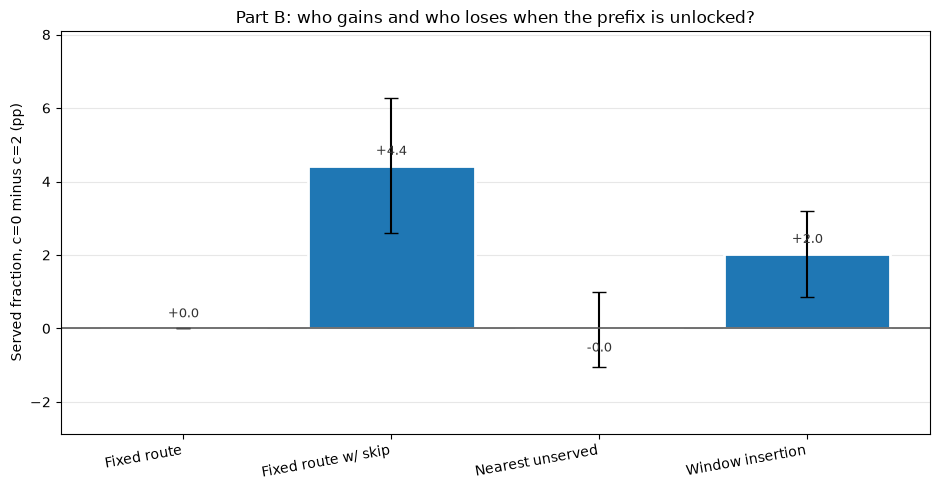

In [7]:
def part_b_trials(name: str, commitment: int) -> list[TrialResult]:
    """
    Per-trial results for one policy at one commitment level.
    :param name: Policy display name from PART_B_POLICIES.
    :param commitment: Commitment level selecting the run.
    :return: That column's per-trial results.
    """
    return part_b_summaries[commitment].results[f"{name} c{commitment}"]


def served_pp(trial: TrialResult) -> float | None:
    """
    Served fraction as percentage points, or None when undefined.
    :param trial: One trial's results.
    :return: Served fraction x 100, or None.
    """
    if trial.kpi.served_fraction is None:
        return None
    return 100.0 * trial.kpi.served_fraction


names = [name for name, _ in PART_B_POLICIES]
deltas, half_widths, p_values = [], [], []
for name in names:
    delta, half_width, p_value = paired_delta(
        part_b_trials(name, 2), part_b_trials(name, 0), served_pp
    )
    deltas.append(delta)
    half_widths.append(half_width)
    p_values.append(p_value)

lines = [
    "| Policy | c=2 served | c=0 served | Delta (pp) | p |",
    "| --- | --- | --- | --- | --- |",
]
for index, name in enumerate(names):
    base = statistics.fmean(
        [v for t in part_b_trials(name, 2) if (v := served_pp(t)) is not None]
    )
    treat = statistics.fmean(
        [v for t in part_b_trials(name, 0) if (v := served_pp(t)) is not None]
    )
    lines.append(
        f"| {name} | {base:.1f} % | {treat:.1f} % "
        f"| {deltas[index]:+.1f} ± {half_widths[index]:.1f} "
        f"| {p_values[index]:.4f} |"
    )
display(Markdown("\n".join(lines)))

# Diverging by sign: the question is who is harmed, so the zero crossing is
# the whole message. Blue gains, amber losses, neutral zero line.
GAIN_COLOUR = "#1f77b4"
LOSS_COLOUR = "#e69f00"

fig, ax = plt.subplots(figsize=(9.5, 5))
positions = list(range(len(names)))
ax.bar(positions, deltas,
       color=[GAIN_COLOUR if d >= 0 else LOSS_COLOUR for d in deltas],
       yerr=half_widths, capsize=5, edgecolor="white", linewidth=2)
ax.axhline(0, color="0.35", linewidth=1.2)
for position, delta in zip(positions, deltas):
    offset = 8 if delta >= 0 else -16
    ax.annotate(f"{delta:+.1f}", xy=(position, delta),
                xytext=(0, offset), textcoords="offset points",
                ha="center", fontsize=9, color="0.2")
ax.set_xticks(positions)
ax.set_xticklabels(names, rotation=10, ha="right")
ax.set_ylabel("Served fraction, c=0 minus c=2 (pp)")
ax.set_title("Part B: who gains and who loses when the prefix is unlocked?")
ax.grid(True, axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.margins(y=0.25)
fig.tight_layout()
plt.show()

## Part C — is the collapse governed by the window?

The mechanism on trial: `_build_projected_state` advances the planning clock by
roughly one hop per committed stop, so the policy reasons from about
`commitment x median_hop` seconds into the future. A request created now
carries a deadline of `now + window`. Once the projection runs further ahead
than the window is wide, every new request is expired before the search starts.

That predicts a breakdown at `commitment ~ window / median_hop`, which for the
three windows here is roughly **4.5, 6.8 and 10.2 stops**. Sweeping one window
cannot test this; moving the window can.

Both the policy's service window and the backend's abandonment threshold are
set to the same value in each block, so every curve sits at its own coherent
operating point rather than drifting off the window/threshold optimum
established in `window-width-sweep-2.ipynb`.

In [8]:
def part_c_label(window: float, commitment: int) -> str:
    """
    Column label for one Part C cell.
    :param window: Service window and abandonment threshold, in seconds.
    :param commitment: Number of leading stops locked during re-planning.
    :return: The label STATS and the summaries are keyed by.
    """
    return f"C W{int(window)} c{commitment}"


part_c_summaries: dict[tuple[float, int], ComparisonSummary] = {}
for window in PART_C_WINDOWS:
    for commitment in PART_C_COMMITMENTS:
        label = part_c_label(window, commitment)
        part_c_summaries[(window, commitment)] = summarize_comparison(
            policies=[(label, window_factory(label, window))],
            graph=graph,
            n_trials=N_TRIALS_C,
            base_seed=BASE_SEED,
            commitment=commitment,
            progress=False,
            max_requests=200,
            capacity=40,
            # Abandonment tracks the policy window deliberately.
            max_wait_s=window,
        )
print(f"{len(part_c_summaries)} columns complete")

24 columns complete


/tmp/ipykernel_21882/4214537223.py:49: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "-o" (-> linestyle='-'). The keyword argument will take precedence.
  abs_served.plot(PART_C_COMMITMENTS, served, "-o", color=colour,
/tmp/ipykernel_21882/4214537223.py:51: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "-o" (-> linestyle='-'). The keyword argument will take precedence.
  abs_reject.plot(PART_C_COMMITMENTS, rejected, "-o", color=colour,
/tmp/ipykernel_21882/4214537223.py:55: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "-o" (-> linestyle='-'). The keyword argument will take precedence.
  norm_served.plot(normalised, [s / served[0] for s in served], "-o",
/tmp/ipykernel_21882/4214537223.py:57: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "-o" (-> linestyle='-'). The key

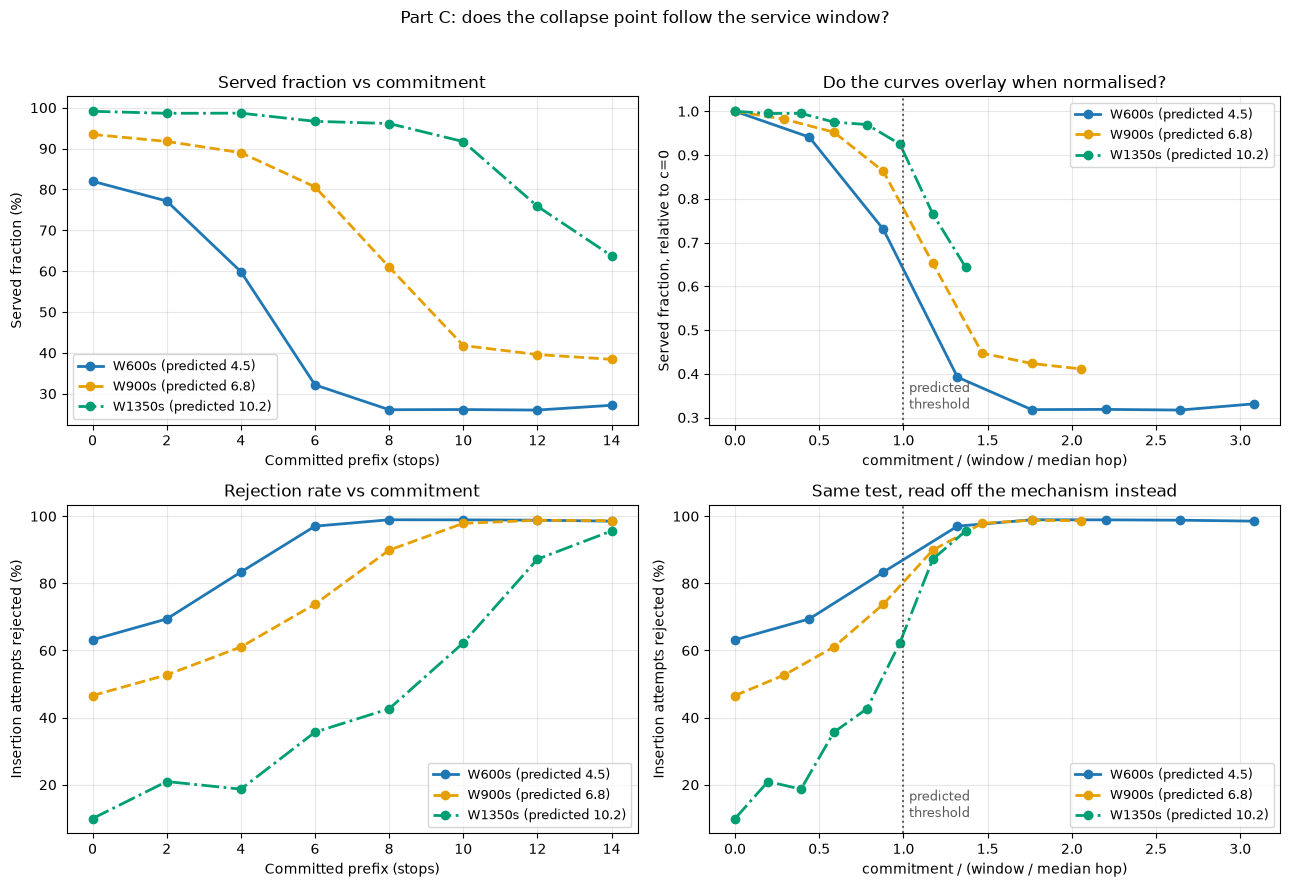

In [9]:
# Fixed categorical order, validated for CVD separation (worst adjacent
# dE 11.4 under protanopia). Dash patterns repeat the distinction so the
# panels survive greyscale printing.
WINDOW_STYLE: dict[float, tuple[str, str]] = {
    600.0: ("#1f77b4", "-"),
    900.0: ("#e69f00", "--"),
    1350.0: ("#009e73", "-."),
}


def served_mean(window: float, commitment: int) -> float:
    """
    Mean served fraction (percentage points) for one Part C cell.
    :param window: Service window in seconds.
    :param commitment: Commitment level.
    :return: Mean served fraction x 100 across trials, or NaN.
    """
    trials = trials_of(part_c_summaries[(window, commitment)])
    values = [v for t in trials if (v := served_pp(t)) is not None]
    return statistics.fmean(values) if values else float("nan")


def rejection_rate(window: float, commitment: int) -> float:
    """
    Share of insertion attempts rejected, as a percentage.
    :param window: Service window in seconds.
    :param commitment: Commitment level.
    :return: Percentage of attempts rejected, or NaN when none were made.
    """
    tally = STATS[part_c_label(window, commitment)]
    if tally.insertion_attempts == 0:
        return float("nan")
    return 100.0 * tally.rejections / tally.insertion_attempts


fig, axes = plt.subplots(2, 2, figsize=(13, 9))
(abs_served, norm_served), (abs_reject, norm_reject) = axes

for window in PART_C_WINDOWS:
    colour, dashes = WINDOW_STYLE[window]
    served = [served_mean(window, c) for c in PART_C_COMMITMENTS]
    rejected = [rejection_rate(window, c) for c in PART_C_COMMITMENTS]
    # Normalised x: 1.0 is where the projection first runs further ahead than
    # the window is wide.
    threshold = window / MEDIAN_HOP_S
    normalised = [c / threshold for c in PART_C_COMMITMENTS]
    label = f"W{int(window)}s (predicted {threshold:.1f})"

    abs_served.plot(PART_C_COMMITMENTS, served, "-o", color=colour,
                    linestyle=dashes, linewidth=2, label=label)
    abs_reject.plot(PART_C_COMMITMENTS, rejected, "-o", color=colour,
                    linestyle=dashes, linewidth=2, label=label)
    # Relative to each curve's own c=0 value, so three different absolute
    # service levels can be overlaid without one dwarfing the others.
    norm_served.plot(normalised, [s / served[0] for s in served], "-o",
                     color=colour, linestyle=dashes, linewidth=2, label=label)
    norm_reject.plot(normalised, rejected, "-o", color=colour,
                     linestyle=dashes, linewidth=2, label=label)

abs_served.set_xlabel("Committed prefix (stops)")
abs_served.set_ylabel("Served fraction (%)")
abs_served.set_title("Served fraction vs commitment")

abs_reject.set_xlabel("Committed prefix (stops)")
abs_reject.set_ylabel("Insertion attempts rejected (%)")
abs_reject.set_title("Rejection rate vs commitment")

norm_served.set_xlabel("commitment / (window / median hop)")
norm_served.set_ylabel("Served fraction, relative to c=0")
norm_served.set_title("Do the curves overlay when normalised?")

norm_reject.set_xlabel("commitment / (window / median hop)")
norm_reject.set_ylabel("Insertion attempts rejected (%)")
norm_reject.set_title("Same test, read off the mechanism instead")

for ax in (norm_served, norm_reject):
    ax.axvline(1.0, color="0.35", linestyle=":", linewidth=1.4)
    ax.annotate("predicted\nthreshold", xy=(1.0, 0.05),
                xycoords=("data", "axes fraction"), xytext=(4, 0),
                textcoords="offset points", fontsize=9, color="0.35")

for ax in axes.ravel():
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=9)

fig.suptitle("Part C: does the collapse point follow the service window?")
fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.96))
plt.show()

## What to look for

### Part A — the win

- **Fulfilled and mean wait both bold at 200 and 500 requests** → confirmed.
  `commitment=0` is better, the effect survives load, and the paired test says
  so with far more confidence than the sweep's overlapping intervals could.
- **Significant at 200 but not 500** → the gain is load-dependent. Worth
  knowing before it becomes a default, since CARLA scenarios are more likely
  to resemble the heavy column.
- **Not significant anywhere** → the sweep's monotone ordering was real but
  the size of the step from 2 to 0 is not resolvable at 20 trials. Raise the
  trial count before acting on it; do not read a null paired test on n=20 as
  evidence of no effect.

Max ride is the row to watch for a nasty surprise: it is the one metric where
`commitment=2` was not clearly worse in the sweep, and a reordering step will
later be judged on it.

### Part B — the blast radius

- **Fixed-route pair near zero, insertion positive** → clean result. The
  prefix is doing nothing for cycle-following policies, and unlocking it helps
  the one policy that re-plans meaningfully. Changing the `run_trial` default
  is then safe.
- **`Nearest unserved` clearly negative** → the prefix is real thrash
  protection for stateless greedy policies. Do **not** change the shared
  default; set `commitment=0` per-experiment for `WindowInsertionPolicy` and
  document why. This is the outcome I would bet on.
- **Anything negative among the fixed-route pair** → surprising, and it would
  mean commitment interacts with cycle-following in a way nobody has
  characterised. Stop and investigate before touching defaults.

### Part C — the collapse

The bottom-right panel is the decisive one, because the rejection rate reads
the mechanism directly rather than its downstream effect.

- **All three curves break at normalised x ~ 1.0** → confirmed, and the design
  rule is causal and transferable: keep the committed prefix below
  `window / median_hop`.
- **Curves overlay at a consistent offset above 1.0** — say all three break
  near 1.4 — → **also a confirmation**, and the likeliest outcome. The
  all-pairs median overstates the hop the bus actually drives, because the
  policy picks nearby stops; the projection therefore advances more slowly
  than the normalisation assumes. The rule survives with a calibration
  constant, and the constant is worth measuring properly (median *consecutive*
  leg rather than median pair).
- **Curves break at the same absolute commitment regardless of window**
  (left column overlays, right column does not) → **refuted**. The collapse is
  geometric — something about this map's structure fails past 6–8 committed
  stops — and it says nothing about other maps.
- **Rejection rate explodes but served fraction holds** → the projection is
  going stale as predicted, but `_progress_fallback` is absorbing it. That
  would make the fallback rate the thing to measure next; see Q3 in
  `window-width-sweep-2.ipynb` for the counter that does it.

### A caveat on reproducibility

Set `PYTHONHASHSEED=0` before launching Jupyter. Both regression checks — Part
A's `c=2 / 200 req` and Part B's `Window insertion c2` — should land on 91.3%
served and 182.7 fulfilled. If they do not, fix that before reading anything
else on the page.